# 02 · Spending, nutrition, preferences and health

Uses `foodspend_core.analytics`, the same functions the API calls. Spending includes discounts, tax, delivery and other charges; home-meal ingredient costs are estimates and excluded. Intake is **logged consumption**, kept separate from purchases.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'backend'))
import pandas as pd, matplotlib.pyplot as plt
from foodspend_core import analytics as A
from foodspend_core.recommender import recommend, simulate, budget_comparison
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = ROOT / 'analysis' / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e1e0d9',
                     'axes.edgecolor': '#c3c2b7', 'font.size': 10, 'figure.dpi': 110})
ds = A.load_processed(ROOT / 'data' / 'processed')
print('SYNTHETIC DATA - generated by analysis/scripts/generate_synthetic_data.py')

SYNTHETIC DATA - generated by analysis/scripts/generate_synthetic_data.py


## Historical spending

In [2]:
s = A.spending_summary(ds)
{k: v for k, v in s.items() if k not in ('by_record_type', 'formula')}

{'period_start': '2025-10-27',
 'period_end': '2026-10-26',
 'period_days': 365,
 'total_spending_inr': 148988.1,
 'transactions': 648,
 'average_transaction_value_inr': 229.92,
 'food_orders': 577,
 'average_food_order_value_inr': 201.2,
 'average_monthly_spending_inr': 12425.2,
 'components_inr': {'items_subtotal': 131221.0,
  'discounts': 3223.0,
  'tax': 4755.1,
  'delivery_fees': 13165.0,
  'other_charges': 3070.0},
 'home_meals_logged': 575,
 'home_meals_estimated_ingredient_cost_inr': 31251.77}

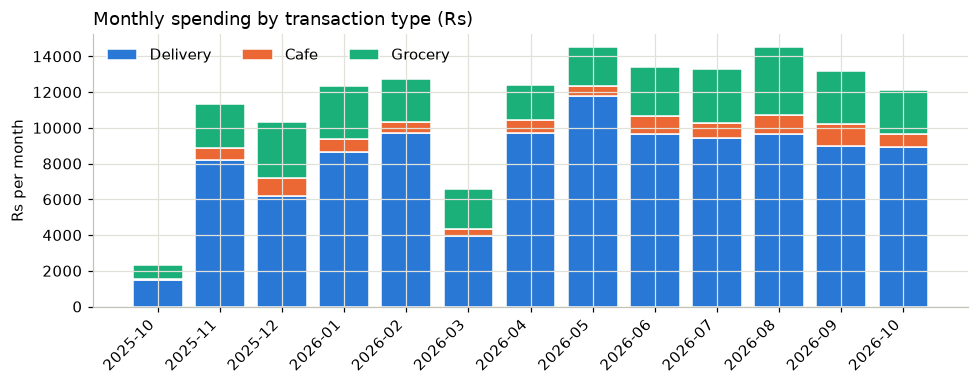

In [3]:
m = A.spending_by_month(ds)
fig, ax = plt.subplots(figsize=(9, 3.6))
bottom = None
for i, (c, l) in enumerate([('delivery_order','Delivery'),('cafe_purchase','Cafe'),('grocery_purchase','Grocery')]):
    ax.bar(m.month, m[c], bottom=bottom, label=l, color=SERIES[i], edgecolor='white', linewidth=1)
    bottom = m[c] if bottom is None else bottom + m[c]
ax.set_title('Monthly spending by transaction type (Rs)', loc='left'); ax.set_ylabel('Rs per month'); ax.legend(ncol=3, frameon=False)
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); fig.savefig(FIG/'monthly_spending.png'); plt.show()

In [4]:
A.spending_by_category(ds)

,label,spending_inr,share_pct
0,North Indian,22190.00,14.89
1,Biryani,18525.00,12.43
2,Snacks,17484.68,11.74
3,Indo-Chinese,15420.00,10.35
4,Bowls & Salads,11980.00,8.04
5,South Indian,11145.00,7.48
6,Fruit,8475.45,5.69
7,Fast Food,7425.00,4.98
8,Eggs,6090.88,4.09
9,Beverages,4755.00,3.19


In [5]:
pd.concat({d: A.spending_by(ds, d) for d in ['meal_type', 'vendor']}).round(1)

label  spending_inr  transactions  average_inr  share_pct
meal_type 0                              lunch       58229.3           215        270.8       39.1
          1                             dinner       38237.6           134        285.4       25.7
          2                     not_applicable       32896.0            71        463.3       22.1
          3                              snack        9817.5           146         67.2        6.6
          4                          breakfast        9807.7            82        119.6        6.6
vendor    0  Neighbourhood Grocery (synthetic)       32896.0            71        463.3       22.1
          1          Punjabi Dhaba (synthetic)       28155.6            97        290.3       18.9
          2          Biryani House (synthetic)       21773.0            69        315.6       14.6
          3            Wok Express (synthetic)       17972.0            70        256.7       12.1
          4          Tiffin Centre (synthetic)       15391.2           119        129.3       10.3
          5         Green Bowl Co. (synthetic)       14101.0            42        335.7        9.5
          6            Corner Cafe (synthetic)        9817.5           146         67.2        6.6
          7            Pizza Point (synthetic)        8881.8            34        261.2        6.0

In [6]:
top = A.purchase_frequency(ds, 10); top

,food_id,purchase_events,quantity,spending_inr,food_name,category
0,F031,110,110.0,2750.00,Masala Chai,Beverages
1,F023,71,71.0,6090.88,Boiled Eggs,Eggs
2,F021,71,71.0,4344.99,Curd (Dahi),Dairy
3,F022,71,426.0,2599.53,Banana,Fruit
4,F033,45,45.0,2290.00,Samosa (2 pcs),Snacks
5,F001,44,44.0,4955.00,Masala Dosa,South Indian
6,F006,43,48.0,12880.00,Chicken Biryani,Biryani
7,F004,42,48.0,11885.00,Paneer Butter Masala with 2 Roti,North Indian
8,F013,40,48.0,8930.00,Veg Hakka Noodles,Indo-Chinese
9,F026,36,36.0,9249.86,Mixed Nuts,Snacks


In [7]:
A.meal_source_pattern(ds)

record_type,meal_type,cafe_purchase,delivery_order,home_meal
0,breakfast,0,82,211
1,dinner,0,134,194
2,lunch,0,215,109
3,snack,146,0,61


## Nutrition (logged consumption vs documented targets)

In [8]:
ns = A.nutrition_summary(ds)
print(ns['basis'])
print('Days logged:', ns['days_logged'], '/', ns['period_days'])
pd.DataFrame(ns['goals'])[['goal_name','average_logged','target','unit','pct_of_target','status']]

Logged consumption (meal records x portion consumed). Days without logs are excluded; unlogged food is not represented, so averages are likely underestimates.
Days logged: 346 / 365


,goal_name,average_logged,target,unit,pct_of_target,status
0,Increase protein toward RDA,50.9,65.5,g/day,77.7,Below target
1,Increase dietary fibre,17.4,30.0,g/day,58.0,Below target
2,Keep energy within estimated requirement,1434.1,2110.0,kcal/day,68.0,Within range


In [9]:
pd.DataFrame(ns['energy_distribution'])[['indicator','value','lower','upper','status']]

,indicator,value,lower,upper,status
0,fat_energy_pct,31.7,NaN,30.0,Above target
1,carb_energy_pct,54.0,45.0,65.0,Within range


In [10]:
ns['completeness']

{'meal_items': 1446,
 'meal_items_unknown_consumption': 17,
 'meal_items_unknown_fiber': 57,
 'foods_with_unknown_nutrients': ['F013', 'F016'],
 'grocery_items_consumption_unknown': 309}

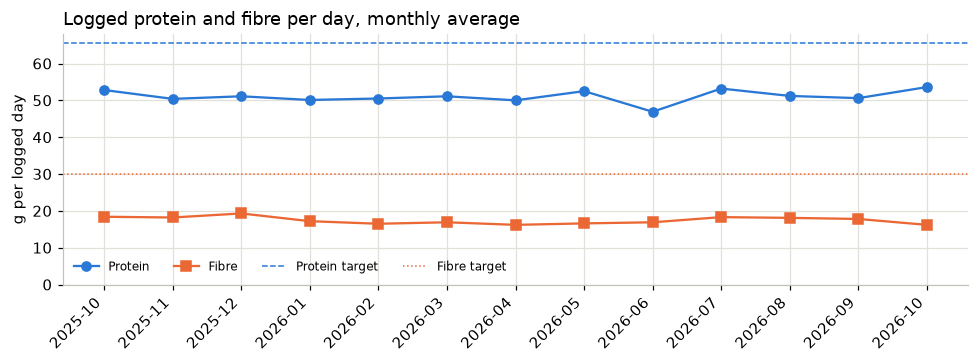

In [11]:
t = A.nutrition_trend(ds, 'M')
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(t.period, t.protein_g, marker='o', color=SERIES[0], label='Protein')
ax.plot(t.period, t.fiber_g, marker='s', color=SERIES[1], label='Fibre')
g = {r['nutrient']: r['target'] for r in ns['goals']}
ax.axhline(g['protein_g'], ls='--', color=SERIES[0], lw=1, label='Protein target')
ax.axhline(g['fiber_g'], ls=':', color=SERIES[1], lw=1, label='Fibre target')
ax.set_ylim(0); ax.set_ylabel('g per logged day')
ax.set_title('Logged protein and fibre per day, monthly average', loc='left'); ax.legend(ncol=4, frameon=False, fontsize=8)
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); fig.savefig(FIG/'nutrition_trend.png'); plt.show()

## Preferences (explicit feedback, kept separate from purchases)

In [12]:
A.preference_summary(ds)

{'feedback_records': 206,
 'foods_rated': 37,
 'average_rating': 3.93,
 'rating_distribution': {2: 9, 3: 44, 4: 106, 5: 47},
 'groups': {'Positive': 24,
  'Neutral': 9,
  'Negative': 3,
  'No feedback': 3,
  'Negative (avoid)': 1},
 'spearman_rating_vs_purchases': 0.44,
 'note': 'Purchase counts are shown beside ratings but are never used as evidence of liking.'}

In [13]:
p = A.preference_table(ds)
p[['food_name','n_ratings','mean_rating','latest_label','preference_group','purchase_events','logged_eaten_events']].head(40)

,food_name,n_ratings,mean_rating,latest_label,preference_group,purchase_events,logged_eaten_events
0,Masala Dosa,16,4.31,liked,Positive,44,43
4,Dal Tadka with Jeera Rice,16,4.00,liked,Positive,30,28
5,Chicken Biryani,13,4.62,liked,Positive,43,40
30,Masala Chai,13,4.15,acceptable,Neutral,110,103
26,"Home Dal, Rice and Sabzi Thali",11,3.82,liked,Positive,0,258
11,Egg Curry with 2 Roti,11,3.64,acceptable,Neutral,24,22
13,Chicken Fried Rice,10,3.70,acceptable,Neutral,30,28
19,Poha,9,4.22,liked,Positive,26,26
1,Idli Sambar (3 idli),9,4.00,liked,Positive,25,24
3,Paneer Butter Masala with 2 Roti,8,4.38,liked,Positive,42,42


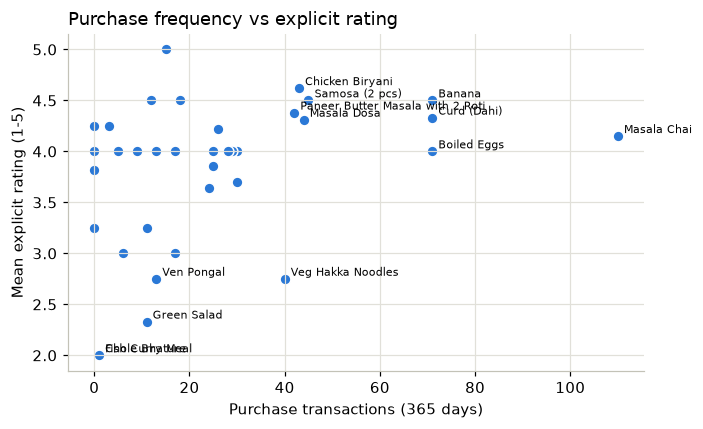

In [14]:
r = p[p.n_ratings > 0]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(r.purchase_events, r.mean_rating, color=SERIES[0], edgecolor='white', s=50)
for _, x in r[(r.purchase_events > 35) | (r.mean_rating < 3)].iterrows():
    ax.annotate(x.food_name, (x.purchase_events, x.mean_rating), fontsize=7, xytext=(4, 2), textcoords='offset points')
ax.set_xlabel('Purchase transactions (365 days)'); ax.set_ylabel('Mean explicit rating (1-5)')
ax.set_title('Purchase frequency vs explicit rating', loc='left'); plt.tight_layout(); fig.savefig(FIG/'rating_vs_purchases.png'); plt.show()

## Health indicators (simulated; associations only)

In [15]:
pd.DataFrame(A.health_summary(ds))[['indicator','unit','measurements','first_date','first_value','latest_date','latest_value','change','reference_lower','reference_upper','latest_status']]

,indicator,unit,measurements,first_date,first_value,latest_date,latest_value,change,reference_lower,reference_upper,latest_status
0,bmi,kg/m2,41,2025-11-02,27.8,2026-10-25,26.7,-1.1,18.5,24.9,Above target
1,diastolic_bp,mmHg,11,2025-11-03,88.0,2026-10-02,77.0,-11.0,NaN,79.0,Within range
2,fasting_glucose,mg/dL,4,2025-11-10,104.0,2026-08-24,97.0,-7.0,70.0,99.0,Within range
3,systolic_bp,mmHg,11,2025-11-03,127.0,2026-10-02,124.0,-3.0,NaN,119.0,Above target
4,waist_circumference,cm,12,2025-11-03,97.1,2026-10-02,92.1,-5.0,NaN,89.9,Above target
5,weight,kg,41,2025-11-02,82.2,2026-10-25,78.9,-3.3,NaN,NaN,Insufficient data


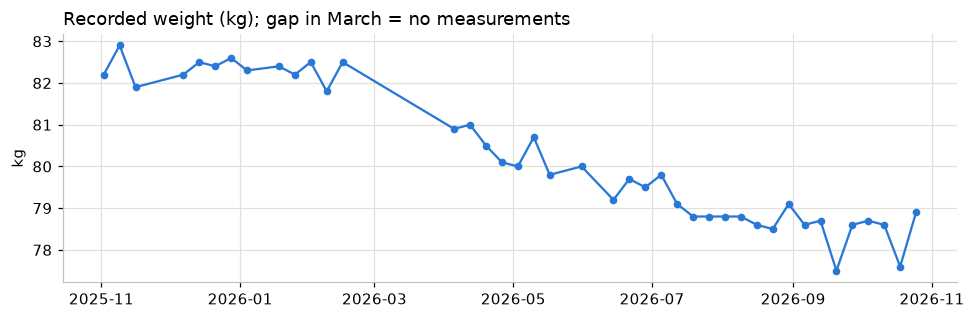

In [16]:
w = A.health_series(ds).query("indicator == 'weight'")
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(w.measurement_date, w.value, marker='o', ms=4, color=SERIES[0])
ax.set_ylabel('kg'); ax.set_title('Recorded weight (kg); gap in March = no measurements', loc='left')
plt.tight_layout(); fig.savefig(FIG/'weight.png'); plt.show()

## Key findings (computed)

In [17]:
for f in A.key_findings(ds):
    print('-', f['title'] + ':', f['detail'])

- Delivery dominates spending: Delivery orders account for Rs 106,275 of Rs 148,988 (71%) across 431 orders. Tax, delivery and platform charges add Rs 20,990 (14.1% of spending); discounts saved Rs 3,223.
- Logged protein is below target: Average logged intake is 50.9 g/day vs a documented target of 65.5 (77.7%), over 346 logged days. Logging is incomplete, so true intake may be higher.
- Logged fibre is below target: Average logged intake is 17.4 g/day vs a documented target of 30 (58.0%), over 346 logged days. Logging is incomplete, so true intake may be higher.
- Frequent purchases are not the same as preferences: Veg Hakka Noodles is #9 by purchase count (40 purchases) but has a mean rating of 2.8/5 and latest label 'disliked'. Spearman correlation between rating and purchase count across rated foods: 0.44.
- Well-rated options are under-used: Sprouts Chaat is rated 4.2/5 (4 ratings) yet was purchased only 3 times.
- Weight trend (association only): Recorded weight changed by -3.3 